# Homework - Everything & Then Some

**Objective:** Predict `repeat_purchase_90d` (binary classification) using `train.csv` and generate predictions for `test.csv`.

## Section 1 – Importing and exploring the data

In this first part, we will simply look at the data, without altering it. The steps are:

1. Load the files
2. Understand the structure (which columns exist and their data types)
3. Examine the distribution of the target variable
4. Check for missing values
5. Review the dates (train vs. test)

### 1.0 Libraries and configuration

We import only the essentials:
- `pandas` for working with tables
- `numpy` for numerical calculations
- `matplotlib` for plots

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Semente aleatória: garante que, mais tarde, os resultados são reprodutíveis
SEED = 42
np.random.seed(SEED)

# Nome da coluna que queremos prever (guardamos numa variável para não a escrever mil vezes)
TARGET = "repeat_purchase_90d"

### 1.1 Loading the files

We have four CSV files:
- `train.csv`: past purchases including the target (this is what the model learns from)
- `test.csv`: purchases for which we need to predict the target (it does not contain the target)
- `clientes.csv`: auxiliary information about each customer (optional, linked via `customer_id`)
- `sample_submission.csv`: an example of the format in which we must submit our predictions

In [9]:
# Load the datasets
train = pd.read_csv("../hdata/train.csv")
test = pd.read_csv("../hdata/test.csv")
clientes = pd.read_csv("../hdata/clientes.csv")
sample_sub = pd.read_csv("../hdata/sample_submission.csv")

# Inspect dataset dimensions
print("train      :", train.shape)
print("test       :", test.shape)
print("clientes   :", clientes.shape)
print("sample_sub :", sample_sub.shape)

train      : (6534, 39)
test       : (986, 38)
clientes   : (1143, 13)
sample_sub : (986, 2)


**What we see:** the training set has 39 columns, and the test set has 38. The difference of one column must be the target, since it is absent from the test set. Let’s confirm this right away.

### 1.2 Table structure

First, we confirm that the training and test sets have the same columns, with the exception of the target variable.
This is important: if a column were missing from the test set, the model would not be able to use it.

In [10]:
cols_only_train = set(train.columns) - set(test.columns)
cols_only_test = set(test.columns) - set(train.columns)

print("Columns only in train:", cols_only_train)
print("Columns only in test :", cols_only_test)

Columns only in train: {'repeat_purchase_90d'}
Columns only in test : set()


Now, we group the columns by type of information. This does not change the data in any way,
it simply helps organize our line of thought and allows us to use these lists later on.

In [11]:
# Numerical columns (current purchase values ​​and customer history)
num_cols = train.select_dtypes(include="number").columns.difference([TARGET, "ID", "customer_id"]).tolist()

# Text columns (categories)
cat_cols = ["payment_type", "salesperson", "commercial_zone",
            "transport_method", "warehouse", "document_series"]

# "Suspicious" or special columns, which we do not treat as standard variables
id_cols = ["ID", "customer_id"]       # identifiers
date_col = "purchase_date"            # date (currently in text format)
noise_col = "random_noise"            # the name suggests pure noise; we will test this later

# Since 'random_noise' is numerical, it appeared in the list of numerical columns; we remove it to keep it separate
num_cols = [c for c in num_cols if c != noise_col]

print(f"{len(num_cols)} numerical | {len(cat_cols)} categorical | {len(id_cols)} identifiers | 1 date | 1 noise")
print("\nNumerical:", num_cols)

28 numerical | 6 categorical | 2 identifiers | 1 date | 1 noise

Numerical: ['Custo', 'N_ Detalhes', 'Total Bruto', 'Total Desc_ Global', 'Total Desc_ Linha', 'Total Imp_', 'Total Liquido', 'Total Portes', 'Total a Pagar', 'customer_tenure_days', 'days_since_previous_purchase', 'invoice_count_current_purchase', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_mean_purchase_value', 'prior_min_purchase_value', 'prior_purchase_count', 'prior_std_gap_days', 'prior_std_purchase_value', 'prior_total_spend', 'purchase_count_180d', 'purchase_count_30d', 'purchase_count_365d', 'purchase_count_90d', 'spend_180d', 'spend_30d', 'spend_365d', 'spend_90d']


Let’s see how many distinct values ​​each categorical column has (its cardinality).
This determines how we will convert them into numbers later on: a column with 2 categories
is straightforward, whereas one with 80 requires more effort.

In [12]:
print(train[cat_cols].nunique().sort_values(ascending=False))

transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2
dtype: int64


**What we see:** `transport_method` has about 80 categories, which is far more than the others.
If we were to create a separate column for each category, we would end up with 80 columns for this variable alone.
We’ll keep this in mind for the preprocessing stage.

### 1.3 The target: `repeat_purchase_90d`

The target is 1 if the customer made a repeat purchase within the following 90 days, and 0 otherwise.
We need to determine whether the classes are **balanced**, as this influences the choice of metric
(in the case of highly imbalanced classes, *accuracy* can be misleading).

                        n  proportion
repeat_purchase_90d                  
0                    2880       0.441
1                    3654       0.559


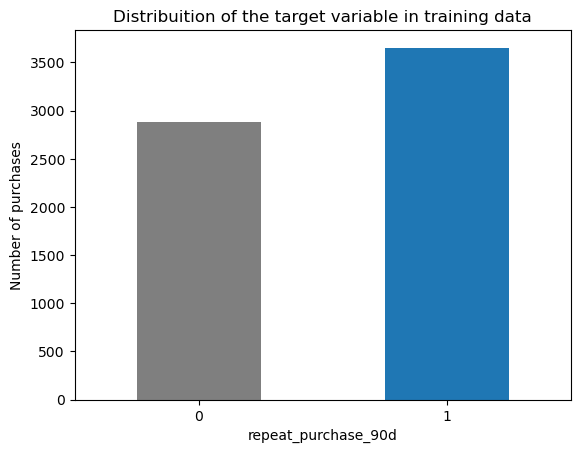

In [13]:
count = train[TARGET].value_counts().sort_index()
proportion = train[TARGET].value_counts(normalize=True).sort_index().round(3)

print(pd.DataFrame({"n": count, "proportion": proportion}))

# Gráfico de barras simples
ax = count.plot(kind="bar", color=["tab:gray", "tab:blue"], rot=0)
ax.set_title("Distribuition of the target variable in training data")
ax.set_xlabel("repeat_purchase_90d")
ax.set_ylabel("Number of purchases")
plt.show()

**What we see:** approximately 56% 1s and 44% 0s. The classes are reasonably balanced,
so we do not need any special balancing techniques. Even so, we will use
metrics beyond just *accuracy* for evaluation (for example, F1 and ROC-AUC).

### 1.4 Missing values

A missing value (`NaN`) can arise for very different reasons:
- **error/empty row:** the record is incomplete;
- **structural absence:** the value does not exist by definition (e.g., a customer making their first purchase cannot have a "standard deviation of previous purchases").

Treating both cases in the same way would be a mistake; therefore, we first **measure** them.

In [14]:
def missing_table(df):
    # Number and % of missing values by column, only for columns that have any missing values
    n = df.isna().sum()
    pct = (df.isna().mean() * 100).round(1)
    out = pd.DataFrame({"n_missing": n, "%": pct})
    return out[out["n_missing"] > 0].sort_values("n_missing", ascending=False)

print("=== TRAIN ===")
print(missing_table(train))
print("\n=== TEST ===")
print(missing_table(test))

=== TRAIN ===
                                n_missing     %
prior_std_gap_days                   1478  22.6
prior_mean_gap_days                  1308  20.0
prior_std_purchase_value             1113  17.0
prior_mean_purchase_value             862  13.2
days_since_previous_purchase          861  13.2
prior_min_purchase_value              668  10.2
prior_max_purchase_value              668  10.2
transport_method                      261   4.0
payment_type                          260   4.0
spend_365d                            260   4.0
warehouse                             260   4.0
salesperson                           259   4.0
commercial_zone                        65   1.0
spend_30d                              65   1.0
purchase_count_365d                    65   1.0
spend_180d                             65   1.0
purchase_count_180d                    65   1.0
document_series                        65   1.0
spend_90d                              65   1.0
purchase_date             

**What we see:** in the training set, many columns have exactly **65** missing values.
This recurring number is suspicious: it suggests that the **same 65 rows** are empty in every case.
Let’s verify.

In [15]:
# Columns that are neither identifiers nor the target: if all of these are empty, the row is considered "empty"
columns_info = [c for c in train.columns if c not in [TARGET, "ID", "customer_id"]]

# For each row, how many of these columns have missing values?
absences_per_line = train[columns_info].isna().sum(axis=1)

print("Distribution of the number of missing columns per row (only for rows with at least one missing value):")
print(absences_per_line[absences_per_line > 0].value_counts().sort_index())

Distribution of the number of missing columns per row (only for rows with at least one missing value):
1     1287
2      190
3      354
4      100
5        6
7      511
8       86
9        6
36      65
Name: count, dtype: int64


If there is a large group of rows with almost all columns missing, these are empty rows.
Let’s isolate them and take a look at them (as well as their target values).

In [22]:
# Threshold: more than half of the informative columns are missing
threshold = len(columns_info) / 2
empty_rows = train[absences_per_line > threshold]

print("Number of nearly empty rows in the training set:", len(empty_rows))
print("\nTarget values ​​in these rows:")
print(empty_rows[TARGET].value_counts())

# Just to see what they look like
empty_rows[["ID", "customer_id", TARGET, date_col, "Total a Pagar", "payment_type"]].head()

Number of nearly empty rows in the training set: 65

Target values ​​in these rows:
repeat_purchase_90d
1    33
0    32
Name: count, dtype: int64


,ID,customer_id,repeat_purchase_90d,purchase_date,Total a Pagar,payment_type
393,10000457,755628,1,NaN,NaN,NaN
484,10000560,755628,1,NaN,NaN,NaN
582,10000678,427118,1,NaN,NaN,NaN
583,10000679,508217,0,NaN,NaN,NaN
748,10000870,427118,0,NaN,NaN,NaN


**What we observe / hypothesis:** these rows have the target variable filled in, but almost nothing else.
Without the other variables, there is nothing for the model to learn from. Furthermore, the test set contains no such rows, so we will not need to make predictions for cases like these.

We have not removed anything yet. That decision is reserved for section 2 (data cleaning), but we are noting it here.

Now, let’s look at the missing values ​​that do not stem from these empty rows—in other words, those that actually exist within the "valid" data.

In [24]:
train_ok = train.drop(empty_rows.index)

print(f"Treino sem as linhas vazias: {train_ok.shape}")
print()
print(missing_table(train_ok))

Treino sem as linhas vazias: (6469, 39)

                              n_missing     %
prior_std_gap_days                 1413  21.8
prior_mean_gap_days                1243  19.2
prior_std_purchase_value           1048  16.2
prior_mean_purchase_value           797  12.3
days_since_previous_purchase        796  12.3
prior_min_purchase_value            603   9.3
prior_max_purchase_value            603   9.3
transport_method                    196   3.0
spend_365d                          195   3.0
payment_type                        195   3.0
warehouse                           195   3.0
salesperson                         194   3.0


**What we observe:** after removing empty rows, the "genuine" missing values ​​remain:
- `prior_std_gap_days`, `prior_mean_gap_days`, `prior_std_purchase_value`, etc.: typically missing
  when a customer has **few prior purchases** (it is not possible to calculate a standard deviation with 0 or 1 data points).
- `payment_type`, `salesperson`, `transport_method`, `warehouse`, `spend_365d`: missing values ​​that appear more "standard."

We will test the hypothesis of structural missingness by comparing the number of prior purchases
between those who have a value and those who do not.

In [25]:
# For each "prior_*" column, what percentage of the missing values ​​occurs when the customer has 0 or 1 previous purchases?
prior_cols = ["prior_min_purchase_value", "prior_std_purchase_value", "prior_std_gap_days",
                 "prior_mean_gap_days", "prior_mean_purchase_value", "days_since_previous_purchase"]

linhas = []
for c in prior_cols:
    out_of_stock = train_ok[c].isna()
    few_purchases = train_ok.loc[out_of_stock, "prior_purchase_count"] <= 1
    linhas.append({"coluna": c,
                   "n_out_of_stock": int(out_of_stock.sum()),
                   "% com 0 ou 1 compras anteriores": round(few_purchases.mean() * 100, 1)})

print(pd.DataFrame(linhas).to_string(index=False))

                      coluna  n_out_of_stock  % com 0 ou 1 compras anteriores
    prior_min_purchase_value             603                            100.0
    prior_std_purchase_value            1048                            100.0
          prior_std_gap_days            1413                             74.2
         prior_mean_gap_days            1243                             84.3
   prior_mean_purchase_value             797                             78.2
days_since_previous_purchase             796                             78.1


**What we observe:** the hypothesis is confirmed in part.
- `prior_min_purchase_value` and `prior_std_purchase_value` are only missing when a customer has 0 or 1 prior purchases. This is a **structural** absence: the value does not exist by definition.
- For the remaining columns, the vast majority of missing values ​​(approximately 75% to 85%) also stem from customers with few prior purchases; however, a portion does **not**—specifically, customers with many prior purchases (even over 200) who still lack a `days_since_previous_purchase` value or an average. These missing values ​​have a different origin and warrant a separate analysis in section 2.

Practical conclusion: the absence is meaningful, so we should not simply fill in missing values ​​with the average without further consideration.
A sound approach would be to create an "is missing" indicator (0/1) alongside the imputed value.

### 1.5 Dates: train vs. test

The `purchase_date` column is in text format. We convert it to a date format so that we can compare when the purchases in the training and test sets occur.
This is crucial for deciding how to evaluate the model.

In [28]:
# errors="coerce": se alguma data não for válida, vira NaT (a "NaN" das datas) em vez de dar erro
train["purchase_date_dt"] = pd.to_datetime(train[date_col], errors="coerce")
test["purchase_date_dt"] = pd.to_datetime(test[date_col], errors="coerce")

print("TRAIN:", train["purchase_date_dt"].min().date(), "->", train["purchase_date_dt"].max().date())
print("TEST:", test["purchase_date_dt"].min().date(), "->", test["purchase_date_dt"].max().date())

TRAIN: 2015-07-11 -> 2025-02-15
TEST: 2025-05-24 -> 2026-10-06


**What we see:** the training period ends in February 2025, while the testing period begins only in May 2025.
In other words, the testing period takes place in the future relative to the training period. We will examine the number of purchases per year
and the repurchase rate per year during the training period.

                  treino  teste
purchase_date_dt               
2015.0               335      0
2016.0               420      0
2017.0               670      0
2018.0               716      0
2019.0               646      0
2020.0               670      0
2021.0               782      0
2022.0               628      0
2023.0               767      0
2024.0               757      0
2025.0                78    465
2026.0                 0    521


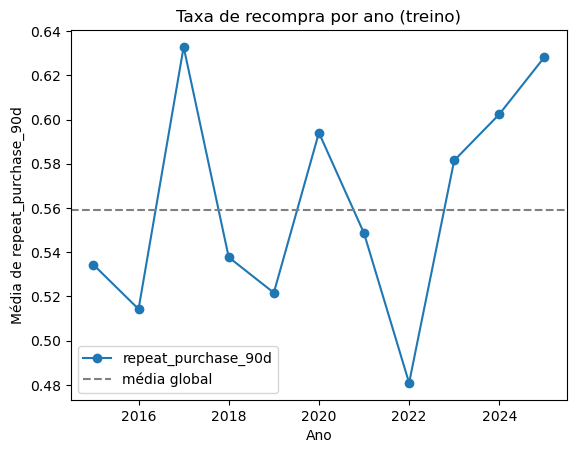

In [29]:
# Nº de compras por ano, treino vs teste
train_per_year = train["purchase_date_dt"].dt.year.value_counts().sort_index()
test_per_year = test["purchase_date_dt"].dt.year.value_counts().sort_index()
print(pd.DataFrame({"treino": train_per_year, "teste": test_per_year}).fillna(0).astype(int))

# Taxa de recompra (média do alvo) por ano, só no treino
year_tax = train.groupby(train["purchase_date_dt"].dt.year)[TARGET].mean()

ax = year_tax.plot(marker="o")
ax.axhline(train[TARGET].mean(), color="gray", linestyle="--", label="média global")
ax.set_title("Taxa de recompra por ano (treino)")
ax.set_xlabel("Ano")
ax.set_ylabel("Média de repeat_purchase_90d")
ax.legend()
plt.show()

**What we observe:** the repurchase rate varies over the years (between approximately 48% and 63%), with no clear trend.
The crucial point is this: since the test set lies in the future, random cross-validation
may yield an **overly optimistic** estimate. In Section 4, we will instead use temporal validation
(training on past data and validating on more recent purchases).